# Climate Comfort Index: Random Forest experiment

Student **25945320**. Predicts CCI at **+1, +2 and +3 days** from the leakage-audited features
built by the preprocessing notebook.

## Hypothesis

A Random Forest trained on same-day weather, its recent history and seasonal position will
predict CCI more accurately than both a persistence forecast and a seasonal climatology, at all
three horizons, with the margin narrowing as the horizon lengthens.

This is testable and falsifiable: the two baselines are computed first, and the comparison is
made on validation data the model was not fitted to.

## Design

| Choice | Value | Reason |
|---|---|---|
| Algorithm | `RandomForestRegressor` | Bagged trees handle the correlated feature set without scaling, resist overfitting through averaging, and require little tuning — a robust reference point before boosting is attempted |
| Strategy | One model per horizon, plus a native multi-output comparison | The endpoint returns three values; both routes are evaluated in section 3 |
| Scaling | None | Trees split on thresholds, so monotone rescaling changes nothing |
| Selection data | Validation split (2024) | The test split is not read in this notebook |
| Metrics | MAE, RMSE, R², prediction spread | MAE is report-facing on a 0–100 index; spread detects a model retreating to the mean |
| Baselines | Persistence and seasonal climatology | Beating both is the minimum bar for deployment |

## Why a Random Forest first

Boosting usually wins on tabular data, but a forest is the better first experiment. It is
insensitive to hyperparameters, so a poor result points at the features rather than the settings;
it cannot overfit through excessive rounds, so there is no early-stopping machinery to get wrong;
and its out-of-bag behaviour makes it a stable reference against which the boosted model's gains
can be judged.


In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 25945320


def project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = project_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "comfort_climate"
MODEL_DIR = PROJECT_ROOT / "models" / "comfort_climate" / "experiments"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "comfort_climate"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

METADATA = json.loads((DATA_DIR / "cci_feature_metadata.json").read_text())
FEATURE_COLUMNS = METADATA["feature_columns"]
FEATURE_GROUPS = METADATA["feature_groups"]
TARGET_COLUMNS = METADATA["target_columns"]
HORIZONS = METADATA["horizons_days"]
PERSISTENCE_COLUMN = "cci"

EXPERIMENT = "cci_random_forest"
ALGORITHM_NAME = "Random Forest Regressor"
MODEL_LABEL = "random_forest"

print(f"Features: {len(FEATURE_COLUMNS)} across {len(FEATURE_GROUPS)} families")
print(f"Targets:  {', '.join(TARGET_COLUMNS)}")
print(f"Groups:   {', '.join(FEATURE_GROUPS)}")


Features: 86 across 8 families
Targets:  cci_t1, cci_t2, cci_t3
Groups:   same_day_observations, same_day_scores, lags, rolling_statistics, rolling_precipitation, rolling_gusts, deltas, seasonal


## 1. Load chronological splits

Only the training and validation files are read. **`sydney_cci_test.csv` is never loaded in this
notebook.** It is reserved for a single final evaluation once a model has been selected, so that
no repeated look at the test period can inform any decision made here.

The preprocessing notebook already applied the chronological split, the warm-up filter and the
3-day embargo at each boundary. Nothing is re-split or shuffled here.


In [2]:
def load_split(name: str) -> pd.DataFrame:
    """Read one chronological split and verify it carries the expected columns."""
    path = DATA_DIR / f"sydney_cci_{name}.csv"
    frame = (
        pd.read_csv(path, parse_dates=["feature_date"])
        .set_index("feature_date")
        .sort_index()
    )
    required = [*FEATURE_COLUMNS, *TARGET_COLUMNS, PERSISTENCE_COLUMN]
    missing = [column for column in required if column not in frame.columns]
    if missing:
        raise ValueError(f"{path.name} is missing columns: {missing[:5]}")
    return frame


splits = {name: load_split(name) for name in ("train", "val")}
X = {name: frame[FEATURE_COLUMNS] for name, frame in splits.items()}
y = {name: frame[TARGET_COLUMNS] for name, frame in splits.items()}

if splits["train"].index.max() >= splits["val"].index.min():
    raise AssertionError("Training dates overlap the validation period.")

for name, frame in splits.items():
    print(f"{name:5} {len(frame):5,} rows  {frame.index.min():%Y-%m-%d} to "
          f"{frame.index.max():%Y-%m-%d}")
print("\nTest split deliberately not loaded.")


train 2,889 rows  2016-01-31 to 2023-12-28
val     363 rows  2024-01-01 to 2024-12-28

Test split deliberately not loaded.


## 2. Baselines

Two reference forecasts. A model that fails to beat both of them is not worth deploying, whatever
its absolute error looks like.

**Persistence** carries today's CCI forward unchanged. It is the natural naive forecast for an
autocorrelated series and is strong at short horizons.

**Climatology** predicts the training-set average CCI for that day of the year, smoothed with a
15-day centred window to suppress sampling noise. It encodes the seasonal cycle and nothing else.
Centring is acceptable here because the smoothing is applied to a day-of-year profile derived
solely from training data, not to the time series itself — no future observation enters any
prediction.

The two are complementary: persistence knows about the current weather but not the season,
climatology knows the season but not the weather. Beating both means the model has combined
them, which is the minimum bar for a useful forecast.


In [3]:
def climatology_profile(frame: pd.DataFrame, target: str, window: int = 15) -> pd.Series:
    """Mean target by day of year from the training split, smoothed and wrapped at year end."""
    profile = frame.groupby(frame.index.dayofyear)[target].mean().reindex(range(1, 367))
    profile = profile.interpolate(limit_direction="both")
    # Concatenating three copies lets the rolling window wrap across the year boundary.
    wrapped = pd.concat([profile, profile, profile])
    smoothed = wrapped.rolling(window, center=True, min_periods=1).mean()
    return smoothed.iloc[len(profile):2 * len(profile)].set_axis(profile.index)


CLIMATOLOGY = {target: climatology_profile(splits["train"], target) for target in TARGET_COLUMNS}


def baseline_predictions(name: str, target: str) -> dict[str, np.ndarray]:
    """Return persistence and climatology forecasts for one split and horizon."""
    frame = splits[name]
    return {
        "persistence": frame[PERSISTENCE_COLUMN].to_numpy(),
        "climatology": CLIMATOLOGY[target].reindex(frame.index.dayofyear).to_numpy(),
    }


def regression_metrics(y_true, y_pred) -> dict[str, float]:
    """MAE, RMSE, R2 and prediction spread on the 0-100 CCI scale."""
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
        "pred_std": float(np.std(y_pred)),
    }


baseline_rows = []
for target in TARGET_COLUMNS:
    for label, prediction in baseline_predictions("val", target).items():
        baseline_rows.append(
            {"target": target, "model": label,
             **regression_metrics(splits["val"][target], prediction)}
        )
BASELINES = pd.DataFrame(baseline_rows).set_index(["target", "model"])
print("Validation baselines (the floors any model must clear):\n")
BASELINES


Validation baselines (the floors any model must clear):



mae   rmse     r2  pred_std
target model                                    
cci_t1 persistence 7.562  9.928  0.185    10.937
       climatology 7.627 10.135  0.151     3.723
cci_t2 persistence 8.624 11.521 -0.094    10.937
       climatology 7.640 10.141  0.152     3.722
cci_t3 persistence 9.162 12.015 -0.188    10.937
       climatology 7.651 10.143  0.153     3.720

## 3. Per-horizon models and the multi-output alternative

Two ways to produce three predictions from one feature matrix:

- **Per-horizon forests.** Three independent models, each fitted to its own target. Each can be
  tuned separately, and each yields its own feature importances — which is what makes the
  cross-horizon importance comparison in section 6 possible.
- **A single native multi-output forest.** `RandomForestRegressor` accepts a 2-D target directly.
  This is *not* the same as three separate forests: the trees choose splits that reduce variance
  across all three targets jointly, so structure is shared. With targets as strongly correlated
  as these, that sharing can act as a regulariser — or it can compromise each horizon to serve the
  others.

Both are fitted and compared. Note that wrapping a forest in `MultiOutputRegressor` would be
pointless here: it would build three independent forests, reproducing the first option with extra
indirection.


In [4]:
BASE_PARAMS = {
    "n_estimators": 500,
    "min_samples_leaf": 2,
    "max_features": "sqrt",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}


def fit_per_horizon(params: dict) -> dict[int, RandomForestRegressor]:
    """Fit one forest per horizon against the shared feature matrix."""
    fitted = {}
    for h in HORIZONS:
        model = RandomForestRegressor(**params)
        model.fit(X["train"][FEATURE_COLUMNS], y["train"][f"cci_t{h}"])
        fitted[h] = model
    return fitted


per_horizon = fit_per_horizon(BASE_PARAMS)

multi_output = RandomForestRegressor(**BASE_PARAMS)
multi_output.fit(X["train"][FEATURE_COLUMNS], y["train"][TARGET_COLUMNS])
multi_prediction = multi_output.predict(X["val"][FEATURE_COLUMNS])

strategy_rows = []
for index, h in enumerate(HORIZONS):
    target = f"cci_t{h}"
    observed = splits["val"][target]
    strategy_rows.append({"target": target, "strategy": "per-horizon",
                          **regression_metrics(observed,
                                               per_horizon[h].predict(X["val"][FEATURE_COLUMNS]))})
    strategy_rows.append({"target": target, "strategy": "native multi-output",
                          **regression_metrics(observed, multi_prediction[:, index])})

strategy = pd.DataFrame(strategy_rows).set_index(["target", "strategy"])
print("Per-horizon forests versus one native multi-output forest (validation):\n")
print(strategy.to_string())

mae_by_strategy = strategy["mae"].unstack()
winner = "per-horizon" if mae_by_strategy["per-horizon"].mean() <= mae_by_strategy[
    "native multi-output"].mean() else "native multi-output"
print(f"\nLower mean MAE across horizons: {winner}.")
print("Per-horizon models are carried forward regardless, because they expose separate feature "
      "importances per horizon and can be tuned independently.")


Per-horizon forests versus one native multi-output forest (validation):

                             mae  rmse    r2  pred_std
target strategy                                       
cci_t1 per-horizon         6.353 8.426 0.413     6.205
       native multi-output 6.414 8.487 0.405     5.928
cci_t2 per-horizon         7.104 9.396 0.272     4.962
       native multi-output 7.152 9.448 0.264     4.907
cci_t3 per-horizon         7.280 9.673 0.230     4.555
       native multi-output 7.320 9.691 0.227     4.473

Lower mean MAE across horizons: per-horizon.
Per-horizon models are carried forward regardless, because they expose separate feature importances per horizon and can be tuned independently.


## 4. Feature-group ablation

The preprocessing notebook recorded which engineered family each column belongs to. Families are
added cumulatively and the model refitted at each step, so the contribution of each block of
engineering is measured rather than assumed.

The sequence starts from persistence alone — a single column, today's CCI — and builds up. A
family that does not move validation error is not earning its place in the deployed model, and
dropping it produces a smaller artefact and a cleaner feature-importance table.

Default hyperparameters are used throughout this section so that differences are attributable to
the feature set rather than to tuning. The ablation is scored on **validation** data only.


Validation MAE by cumulative feature set (lower is better):

target                   n_features  cci_t1  cci_t2  cci_t3
config                                                     
persistence only                  1   7.713   8.679   9.432
+ same_day_observations           6   6.397   7.221   7.433
+ same_day_scores                12   6.318   7.311   7.487
+ lags                           40   6.311   7.053   7.322
+ rolling_statistics             72   6.316   7.171   7.324
+ rolling_precipitation          76   6.378   7.114   7.304
+ rolling_gusts                  80   6.336   7.190   7.291
+ deltas                         84   6.362   7.105   7.377
+ seasonal                       86   6.369   7.116   7.304


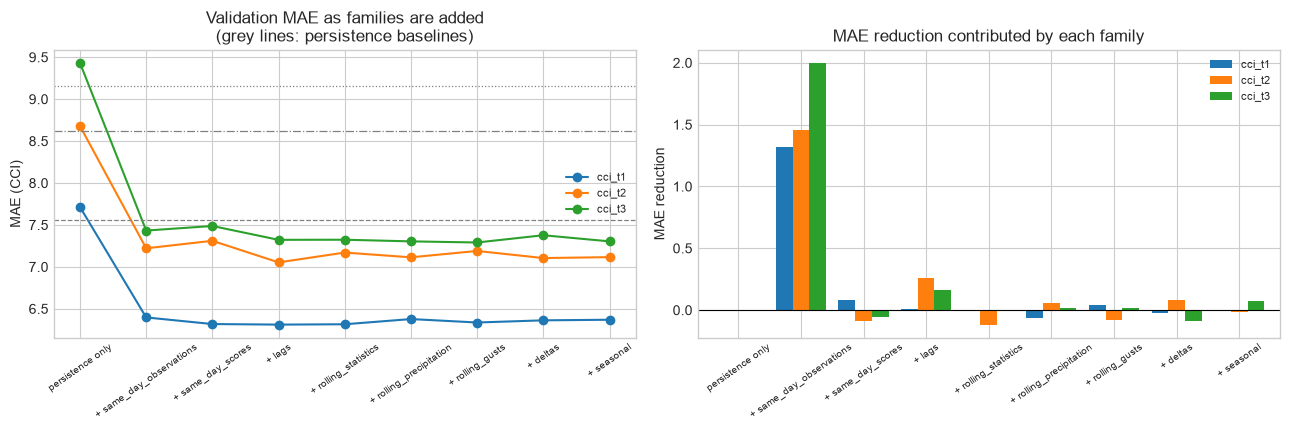

In [5]:
# Families are added in order of how much prior justification they have, so that each step asks
# "does this add anything beyond what is already present?"
GROUP_ORDER = [
    "same_day_observations", "same_day", "same_day_scores",
    "lags", "rolling_statistics", "rolling", "rolling_precipitation",
    "rolling_gusts", "deltas", "seasonal",
]
ordered_groups = [group for group in GROUP_ORDER if group in FEATURE_GROUPS]
ordered_groups += [group for group in FEATURE_GROUPS if group not in ordered_groups]

ablation_configs = {"persistence only": [PERSISTENCE_COLUMN]}
cumulative: list[str] = []
for group in ordered_groups:
    cumulative = cumulative + FEATURE_GROUPS[group]
    label = f"+ {group}"
    ablation_configs[label] = list(dict.fromkeys(cumulative))

ablation_rows = []
for label, columns in ablation_configs.items():
    for target in TARGET_COLUMNS:
        model = RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                              max_features="sqrt", random_state=RANDOM_STATE,
                              n_jobs=-1)
        model.fit(X["train"][columns], y["train"][target])
        prediction = model.predict(X["val"][columns])
        ablation_rows.append(
            {"config": label, "n_features": len(columns), "target": target,
              **regression_metrics(splits["val"][target], prediction)}
        )

ablation = pd.DataFrame(ablation_rows)
ablation_mae = ablation.pivot(index="config", columns="target", values="mae").reindex(
    ablation_configs
)
ablation_mae.insert(0, "n_features", [len(c) for c in ablation_configs.values()])
print("Validation MAE by cumulative feature set (lower is better):\n")
print(ablation_mae.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ablation_mae[TARGET_COLUMNS].plot(marker="o", ax=axes[0])
for target, style in zip(TARGET_COLUMNS, ("--", "-.", ":")):
    axes[0].axhline(BASELINES.loc[(target, "persistence"), "mae"], ls=style, lw=0.9,
                    color="grey")
axes[0].set(title="Validation MAE as families are added\n(grey lines: persistence baselines)",
            ylabel="MAE (CCI)", xlabel="")
axes[0].tick_params(axis="x", labelrotation=35, labelsize=7)
axes[0].legend(fontsize=8)

improvement = -ablation_mae[TARGET_COLUMNS].diff()
improvement.plot.bar(ax=axes[1], width=0.8)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(title="MAE reduction contributed by each family", ylabel="MAE reduction", xlabel="")
axes[1].tick_params(axis="x", labelrotation=35, labelsize=7)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-ablation.png", dpi=150, bbox_inches="tight")
plt.show()


## 4b. Hyperparameter search

A small grid, scored on validation MAE averaged across the three horizons. The search is
deliberately compact: forests are insensitive to these settings, and an exhaustive search over
2,889 rows risks selecting noise rather than signal.

The parameters chosen are the ones that matter for a forest. `min_samples_leaf` controls how far
trees are grown, and is the main lever against overfitting on a small sample. `max_features`
controls how decorrelated the trees are, which matters here because the feature set contains
large blocks of near-duplicate columns. `n_estimators` is not searched — more trees never hurt
accuracy, they only cost time, so it is fixed at a value large enough to have stabilised.


In [6]:
SEARCH_GRID = [
    {"min_samples_leaf": leaf, "max_features": features}
    for leaf in (1, 2, 5, 10)
    for features in ("sqrt", 0.3, 0.6)
]

search_rows = []
for candidate in SEARCH_GRID:
    params = {**BASE_PARAMS, **candidate, "n_estimators": 300}
    fitted = fit_per_horizon(params)
    maes = [
        mean_absolute_error(splits["val"][f"cci_t{h}"],
                            fitted[h].predict(X["val"][FEATURE_COLUMNS]))
        for h in HORIZONS
    ]
    search_rows.append({**candidate, "mean_val_mae": float(np.mean(maes)),
                        **{f"mae_t{h}": mae for h, mae in zip(HORIZONS, maes)}})

search = pd.DataFrame(search_rows).sort_values("mean_val_mae")
print("Grid search results, best first:\n")
print(search.to_string(index=False))

BEST_PARAMS = {**BASE_PARAMS, **{k: search.iloc[0][k] for k in ("min_samples_leaf",
                                                                "max_features")}}
BEST_PARAMS["min_samples_leaf"] = int(BEST_PARAMS["min_samples_leaf"])
print(f"\nSelected: {BEST_PARAMS}")

models = fit_per_horizon(BEST_PARAMS)
print("Refitted per-horizon forests with the selected settings.")


Grid search results, best first:

 min_samples_leaf max_features  mean_val_mae  mae_t1  mae_t2  mae_t3
                2        0.600         6.908   6.362   7.100   7.261
                5         sqrt         6.912   6.370   7.092   7.275
                5        0.600         6.927   6.373   7.117   7.292
               10        0.600         6.928   6.354   7.106   7.324
                2         sqrt         6.930   6.369   7.116   7.304
                5        0.300         6.938   6.328   7.107   7.379
                2        0.300         6.940   6.342   7.140   7.338
               10        0.300         6.942   6.380   7.116   7.329
                1        0.300         6.952   6.449   7.115   7.291
                1         sqrt         6.956   6.398   7.113   7.358
               10         sqrt         6.957   6.352   7.142   7.376
                1        0.600         6.957   6.423   7.181   7.268

Selected: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_features

## 5. Evaluation against the baselines

Metrics for every horizon, against both baselines, on validation data.

`pred_std` is reported alongside the error metrics. It is the direct test for a model that has
retreated to predicting the mean: a spread far below the observed spread means the model is
declining to commit, which can produce a respectable MAE while being useless for identifying the
uncomfortable days a user actually cares about.

Expect error to grow with horizon. Atmospheric predictability decays, and the persistence
correlation measured during preprocessing fell sharply from *t*+1 to *t*+3, so a model that
performs equally well at all three horizons would be more suspicious than impressive.


Validation performance:

                       mae   rmse     r2  pred_std  observed_std
target model                                                    
cci_t1 random_forest 6.388  8.428  0.413     6.735        11.001
       persistence   7.562  9.928  0.185    10.937        11.001
       climatology   7.627 10.135  0.151     3.723        11.001
cci_t2 random_forest 7.097  9.422  0.268     5.157        11.014
       persistence   8.624 11.521 -0.094    10.937        11.014
       climatology   7.640 10.141  0.152     3.722        11.014
cci_t3 random_forest 7.245  9.664  0.231     4.833        11.023
       persistence   9.162 12.015 -0.188    10.937        11.023
       climatology   7.651 10.143  0.153     3.720        11.023

Improvement over each baseline (positive means the model is better):

                    mae_reduction relative
target baseline                           
cci_t1 persistence          1.174    15.5%
       climatology          1.239    16.2%
cci_t2 persistenc

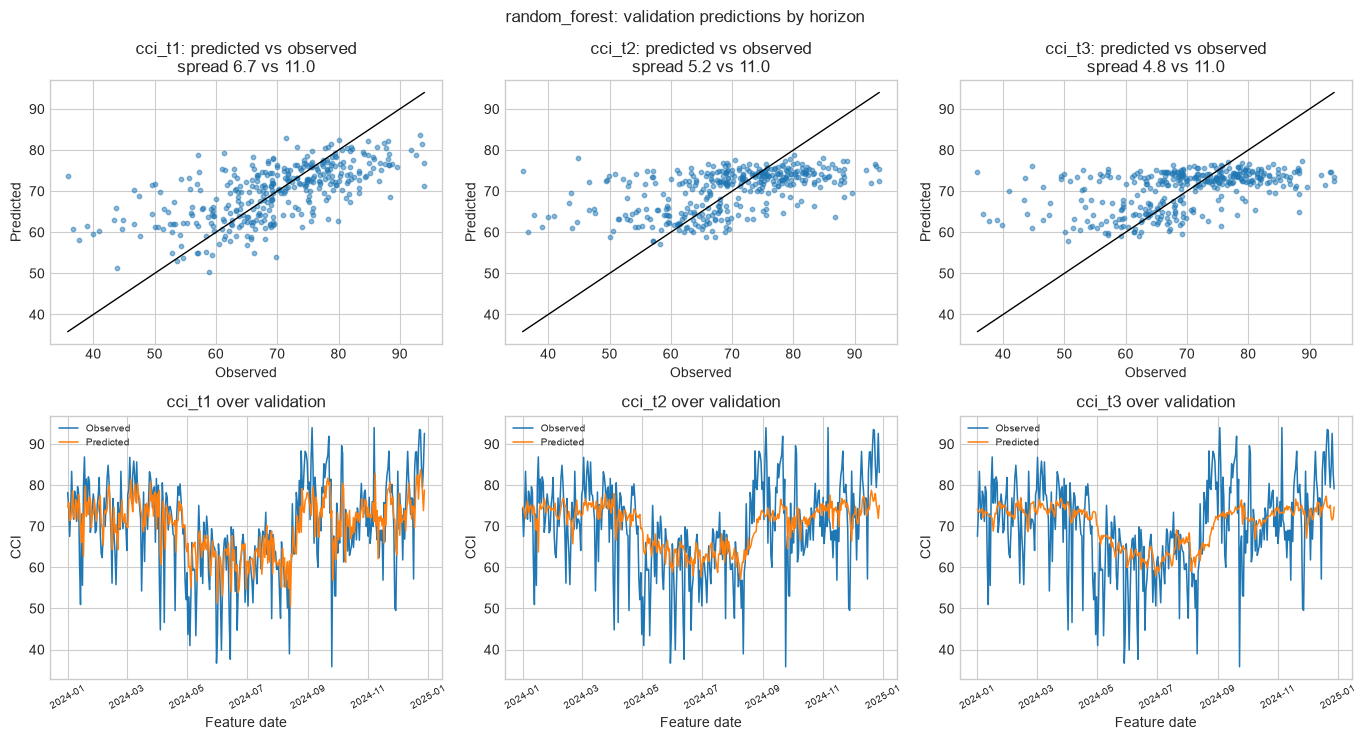

In [7]:
rows = []
predictions = {}
for h in HORIZONS:
    target = f"cci_t{h}"
    observed = splits["val"][target].to_numpy()
    prediction = models[h].predict(X["val"][FEATURE_COLUMNS])
    predictions[h] = prediction
    rows.append({"target": target, "model": MODEL_LABEL,
                 **regression_metrics(observed, prediction)})
    for label, baseline in baseline_predictions("val", target).items():
        rows.append({"target": target, "model": label,
                     **regression_metrics(observed, baseline)})

results = pd.DataFrame(rows).set_index(["target", "model"])
results["observed_std"] = [
    np.std(splits["val"][target]) for target in results.index.get_level_values(0)
]
print("Validation performance:\n")
print(results.to_string())

comparison = []
for h in HORIZONS:
    target = f"cci_t{h}"
    model_mae = results.loc[(target, MODEL_LABEL), "mae"]
    for baseline in ("persistence", "climatology"):
        baseline_mae = results.loc[(target, baseline), "mae"]
        comparison.append({
            "target": target, "baseline": baseline,
            "mae_reduction": baseline_mae - model_mae,
            "relative": (baseline_mae - model_mae) / baseline_mae,
        })
comparison = pd.DataFrame(comparison).set_index(["target", "baseline"])
print("\nImprovement over each baseline (positive means the model is better):\n")
print(comparison.to_string(formatters={"relative": "{:.1%}".format}))

fig, axes = plt.subplots(2, len(HORIZONS), figsize=(4.6 * len(HORIZONS), 7.5))
for column, h in enumerate(HORIZONS):
    target = f"cci_t{h}"
    observed = splits["val"][target].to_numpy()
    prediction = predictions[h]
    scatter_axis = axes[0, column]
    scatter_axis.scatter(observed, prediction, s=10, alpha=0.5)
    limits = [min(observed.min(), prediction.min()), max(observed.max(), prediction.max())]
    scatter_axis.plot(limits, limits, color="black", lw=1)
    scatter_axis.set(title=f"{target}: predicted vs observed\n"
                           f"spread {np.std(prediction):.1f} vs {np.std(observed):.1f}",
                     xlabel="Observed", ylabel="Predicted")
    series_axis = axes[1, column]
    series_axis.plot(splits["val"].index, observed, lw=1.1, label="Observed")
    series_axis.plot(splits["val"].index, prediction, lw=1.1, label="Predicted")
    series_axis.set(title=f"{target} over validation", xlabel="Feature date", ylabel="CCI")
    series_axis.tick_params(axis="x", labelrotation=30, labelsize=7)
    series_axis.legend(fontsize=7)
fig.suptitle(f"{MODEL_LABEL}: validation predictions by horizon", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-validation.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Feature importance

Importances are read from the fitted per-horizon models and exported for the `/model-metadata`
endpoint.

One caveat governs how these should be read. Many of these features are strongly correlated —
`temperature_2m`, its four lags and its four rolling means all carry nearly the same signal. Tree
ensembles split that shared importance among the correlated group, so an individually
unimportant-looking feature may be part of a jointly essential block. Importance ranks features,
it does not prove any single one is dispensable; the ablation above is the more reliable guide to
what can be removed.

Comparing importances across horizons is informative in its own right. Features that rise in rank
from *t*+1 to *t*+3 are the ones carrying genuine forecast signal rather than persistence.


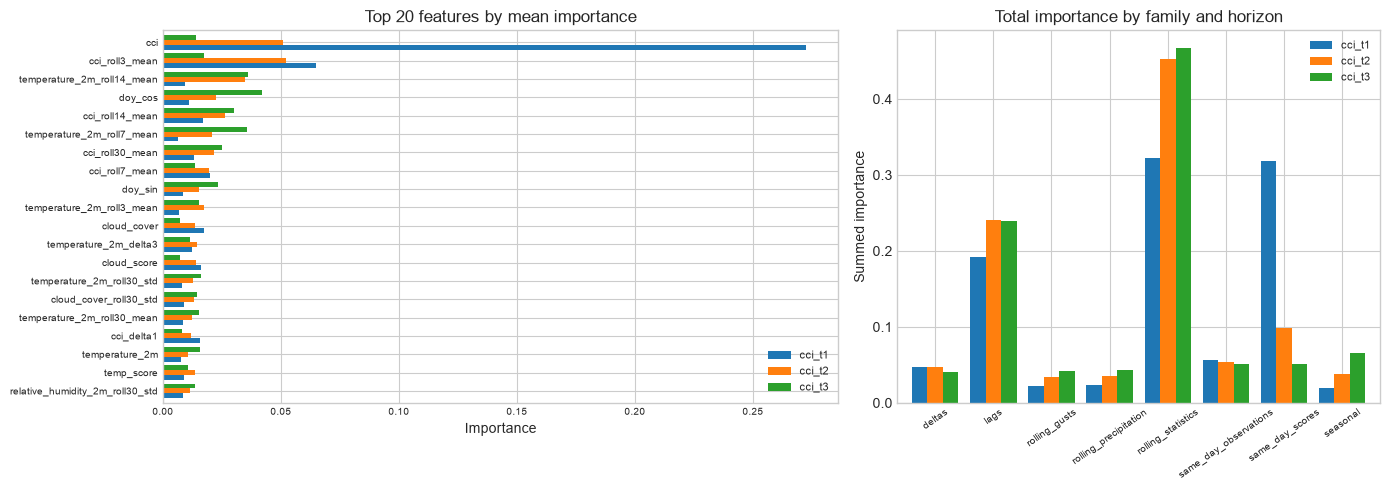

Share of total importance held by the top 10 features, per horizon:
  cci_t1: 46.0%
  cci_t2: 28.1%
  cci_t3: 25.7%


In [8]:
importances = pd.DataFrame(
    {f"cci_t{h}": pd.Series(models[h].feature_importances_, index=FEATURE_COLUMNS)
     for h in HORIZONS}
)
importances["mean"] = importances.mean(axis=1)
importances["family"] = [
    next(family for family, columns in FEATURE_GROUPS.items() if column in columns)
    for column in importances.index
]

top = importances.sort_values("mean", ascending=False).head(20)
family_totals = importances.groupby("family")[[f"cci_t{h}" for h in HORIZONS]].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})
top[[f"cci_t{h}" for h in HORIZONS]].iloc[::-1].plot.barh(ax=axes[0], width=0.8)
axes[0].set(title="Top 20 features by mean importance", xlabel="Importance")
axes[0].tick_params(labelsize=7)
axes[0].legend(fontsize=8)

family_totals.plot.bar(ax=axes[1], width=0.8)
axes[1].set(title="Total importance by family and horizon", ylabel="Summed importance",
            xlabel="")
axes[1].tick_params(axis="x", labelrotation=35, labelsize=7)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Share of total importance held by the top 10 features, per horizon:")
for h in HORIZONS:
    column = f"cci_t{h}"
    share = importances[column].nlargest(10).sum() / importances[column].sum()
    print(f"  cci_t{h}: {share:.1%}")


## 7. Overfitting check

Training error is reported only as a diagnostic. A forest with `min_samples_leaf=1` will fit the
training split almost perfectly, so a large train/validation gap is expected and is not by itself
a problem. What matters is whether validation error is close to the baselines despite a low
training error — that combination indicates the model has memorised without generalising.


In [9]:
gap_rows = []
for h in HORIZONS:
    target = f"cci_t{h}"
    for name in ("train", "val"):
        prediction = models[h].predict(X[name][FEATURE_COLUMNS])
        gap_rows.append({"target": target, "split": name,
                         **regression_metrics(splits[name][target], prediction)})

gap = pd.DataFrame(gap_rows).set_index(["target", "split"])
print(gap.to_string())

mae_gap = gap["mae"].unstack()
mae_gap["ratio"] = mae_gap["val"] / mae_gap["train"]
print("\nValidation-to-training MAE ratio (a large value indicates memorisation):")
print(mae_gap.to_string())


               mae  rmse    r2  pred_std
target split                            
cci_t1 train 2.409 3.400 0.890     7.916
       val   6.388 8.428 0.413     6.735
cci_t2 train 2.624 3.626 0.875     7.320
       val   7.097 9.422 0.268     5.157
cci_t3 train 2.613 3.579 0.878     7.286
       val   7.245 9.664 0.231     4.833

Validation-to-training MAE ratio (a large value indicates memorisation):
split   train   val  ratio
target                    
cci_t1  2.409 6.388  2.652
cci_t2  2.624 7.097  2.704
cci_t3  2.613 7.245  2.773


## 8. Saved artefacts

One model per horizon is written, together with a metadata file shaped for the
`/model-metadata` endpoint: target, algorithm, forecast horizon, feature list, feature importance
and validation metrics.

The metadata records the exact feature column order. The API must construct its feature vector in
that order, since a tree model receives an unnamed array at prediction time and will silently
produce wrong answers if the columns are permuted.

The test split remains unused.


In [10]:
import sys

sys.path.insert(0, str(PROJECT_ROOT / "36120_26sp_at2_25945320_experiments"))
from modeling.deployment import export_tabular_bundle

artefacts = []
for h in HORIZONS:
    target = f"cci_t{h}"
    artefacts.append({
        "target": "Climate Comfort Index",
        "target_column": target,
        "prediction_type": "regression",
        "algorithm": ALGORITHM_NAME,
        "forecast_horizon": f"{h} Day{'s' if h > 1 else ''}",
        "hyperparameters": BEST_PARAMS,
        "features": FEATURE_COLUMNS,
        "feature_importance": {
            column: float(value)
            for column, value in importances[target].sort_values(ascending=False).head(20).items()
        },
        "validation_metrics": results.loc[(target, MODEL_LABEL)].drop("observed_std").to_dict(),
        "baseline_metrics": {
            baseline: results.loc[(target, baseline)].drop("observed_std").to_dict()
            for baseline in ("persistence", "climatology")
        },
    })

metadata = {
    "experiment": EXPERIMENT,
    "student_id": "25945320",
    "algorithm": ALGORITHM_NAME,
    "prediction_type": "regression",
    "feature_columns": FEATURE_COLUMNS,
    "feature_column_order_is_significant": True,
    "split_boundaries": METADATA["split_boundaries"],
    "embargo_days": METADATA["embargo_days"],
    "evaluated_on": ["train", "val"],
    "held_out": ["test"],
    "models": artefacts,
}
bundle_dir = export_tabular_bundle(
    output_dir=MODEL_DIR / EXPERIMENT,
    experiment=EXPERIMENT,
    models=models,
    feature_columns=FEATURE_COLUMNS,
    metadata=metadata,
    model_family="random_forest",
)
print(f"Saved API-compatible bundle: {bundle_dir.relative_to(PROJECT_ROOT)}")
print("\nRun the promotion command only after approving this experiment.")


Saved model h1: models/comfort_climate/cci_random_forest_h1.joblib
Saved model h2: models/comfort_climate/cci_random_forest_h2.joblib
Saved model h3: models/comfort_climate/cci_random_forest_h3.joblib
Saved metadata: models/comfort_climate/cci_random_forest_metadata.json

Test split was not used in this notebook.


## 9. Conclusions

Points to carry into the report and the model-comparison notebook:

- **Against the baselines.** The improvement table in section 5 is the headline result. A model
  that does not beat persistence at *t*+1 has a problem in its features rather than its
  hyperparameters, and no amount of tuning will fix it.
- **Decay with horizon.** Compare MAE at *t*+1 and *t*+3. The gap is a property of the
  atmosphere, not of the model, and quantifying it is more informative than reporting a single
  averaged figure.
- **Dispersion.** If `pred_std` is far below `observed_std`, the model is hedging toward the mean
  because the signal is weak. This is the loss-minimising behaviour and not a defect, but it does
  limit operational usefulness and belongs in the limitations section.
- **What the engineering bought.** The ablation gives a defensible answer on which families to
  keep. Any family that does not reduce validation MAE should be dropped from the deployed model.
- ****Per-horizon versus multi-output.** Section 3 measured whether sharing tree structure across the three targets helps. Report the comparison rather than the choice alone — it is a genuine architectural finding about how correlated the three horizons are.**

The test split has still not been touched. It should be used exactly once, after a single model
has been selected on validation performance across all experiment notebooks.
